# Etapa 5: Visualización y análisis
Gráficos a partir de las tablas Delta guardadas.

In [0]:
spark.sql("USE CATALOG workspace")
spark.sql("USE SCHEMA tp7_peliculas")

import matplotlib.pyplot as plt
from pyspark.sql import functions as F

df = spark.table("peliculas_ratings")
top = spark.table("top_peliculas")
print("Datos cargados:", df.count(), "filas")

Datos cargados: 100818 filas


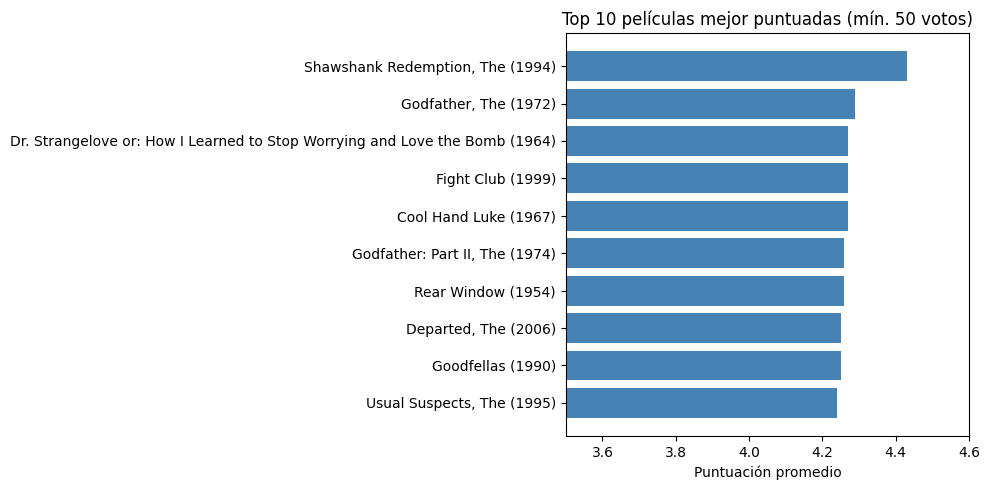

In [0]:
top10 = top.orderBy(F.desc("promedio")).limit(10).toPandas()

plt.figure(figsize=(10, 5))
plt.barh(top10["title"], top10["promedio"], color="steelblue")
plt.gca().invert_yaxis()
plt.xlim(3.5, 4.6)  # el eje arranca en 3.5 para que se noten las diferencias
plt.xlabel("Puntuación promedio")
plt.title("Top 10 películas mejor puntuadas (mín. 50 votos)")
plt.tight_layout()
plt.show()

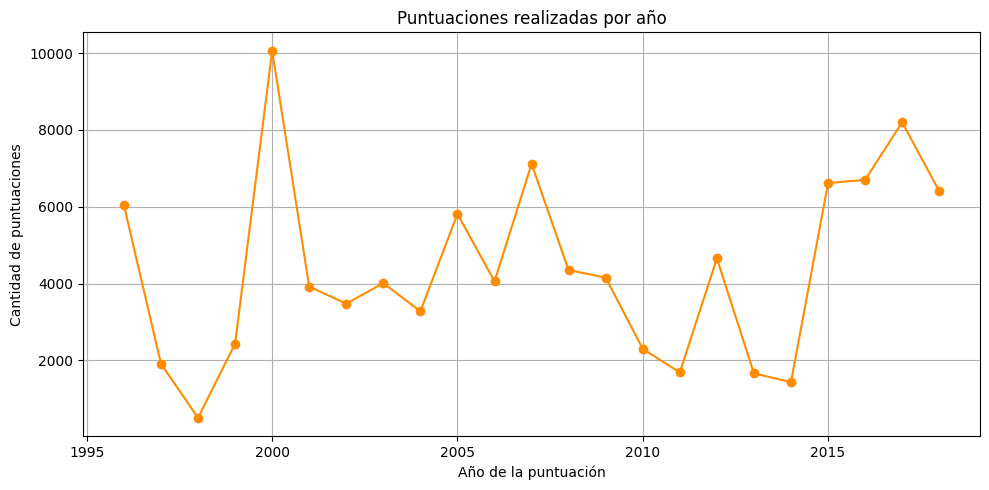

In [0]:
por_anio = df.groupBy("anio_rating").count().orderBy("anio_rating").toPandas()

plt.figure(figsize=(10, 5))
plt.plot(por_anio["anio_rating"], por_anio["count"], marker="o", color="darkorange")
plt.xlabel("Año de la puntuación")
plt.ylabel("Cantidad de puntuaciones")
plt.title("Puntuaciones realizadas por año")
plt.grid(True)
plt.tight_layout()
plt.show()

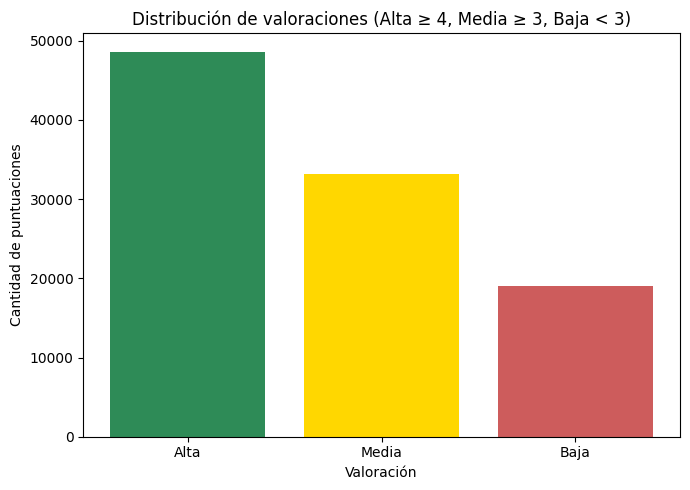

In [0]:
val = df.groupBy("valoracion").count().toPandas()
val = val.set_index("valoracion").loc[["Alta", "Media", "Baja"]].reset_index()

plt.figure(figsize=(7, 5))
plt.bar(val["valoracion"], val["count"], color=["seagreen", "gold", "indianred"])
plt.xlabel("Valoración")
plt.ylabel("Cantidad de puntuaciones")
plt.title("Distribución de valoraciones (Alta ≥ 4, Media ≥ 3, Baja < 3)")
plt.tight_layout()
plt.show()

## Conclusiones

Top mejores películas: entre las mejores películas con al menos 50 puntuaciones, The Shawshank Redemption (1994) lidera con un promedio de 4,43, seguida por The godfather (1972) con 4,29. Son clásicos y la mayoría del top corresponde a películas estrenadas antes del año 2000.

Puntuaciones realizadas por año: las puntuaciones no son uniformes en el tiempo. El pico se registró en el año 2000 con más de 10.000 puntuaciones y el mínimo que fue en 1998. Esto depende de cuando estuvieron activos los usuarios de la muestra y no de la calidad de las películas.

Distribución de valoraciones: los usuarios tienden a puntuar de forma favorable. La mayoría de las calificaciones son altas (4 o más), seguidas por las medias y, en menor medida, por las bajas (menos de 3). Esto explica que el promedio general se ubique en 3,5.

Calidad de datos: el dataset no tenía duplicados ni nulos. Se descartaron 18 puntuaciones de películas sin año en el título. Tras guardar en Delta Lake y volver a leer, se validó que los conteos, nulos, duplicados y rango de puntuaciones eran correctos. 
